# Bloque C - C4: Características cromáticas por célula

**Objetivo:** calcular, para cada eritrocito, las **características de color** que pide el anteproyecto (medias, desvíos, histogramas, proporción de tonos oscuros/violetas y área cromática integrada), más las que surgieron de C1-C3, y analizar cuáles separan mejor parasitadas de sanas. La selección definitiva y los umbrales de clasificación se validan en C5.

**De dónde salen:**
- **C1:** el parásito es oscuro (G, L bajos) y violeta (b bajo, a y S altos). El color *promedio* de la célula separa poco; los **píxeles extremos** (percentiles 5 y 95) separan mejor.
- **C2:** conviene **normalizar por fondo** (balance de blancos), y evaluar **por paciente**, porque juntar pacientes infla los resultados.
- **C3:** la **máscara de manchas oscuras** dentro de la célula detecta parasitadas mucho mejor que cualquier estadístico de la célula entera.

**Cómo lo hacemos:**
1. Recortes de cada célula del GT con la función compartida `celulas_desde_gt`. Usamos el mismo `cell_id` que el Bloque B, para poder unir color y textura.
2. Normalizamos cada recorte por fondo con `color_stain/normalizacion.py` (la misma normalización que usa el pipeline).
3. Calculamos las características **solo para train**. Test queda reservado para la evaluación final, donde se calcularán con estas mismas funciones y parámetros, sin reajustar nada.
4. El análisis de las características también se hace **solo con train**, y es **exploratorio**: la validación por paciente de los criterios de clasificación se hace en C5.
5. Guardamos todo en `results/features_color_gt.csv`.

In [1]:
# BLOQUE C - C4: Características cromáticas por célula

import sys
sys.path.append("..")  # el notebook está en color_stain/, subimos un nivel para poder importar common/

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from common.config import LABEL_PARASITIZED, LABEL_UNINFECTED, LABEL_WBC
from common.io_utils import cargar_subset, cargar_imagen
from common.generar_gt_utils import celulas_desde_gt
from segmentation.preprocess import mascara_circular

CARPETA_RESULTADOS = Path("results")
CARPETA_RESULTADOS.mkdir(exist_ok=True)

COLOR_CLASE = {LABEL_UNINFECTED: "#eb6834", LABEL_PARASITIZED: "#1baf7a"}  # mismos colores que C1

## 1. Normalización por fondo y máscara de C3

La normalización por fondo se importa de `color_stain/normalizacion.py`. Las funciones de las características están en `color_stain/color_features.py`, que es el módulo que usa el pipeline (así el notebook y el pipeline calculan exactamente lo mismo). La máscara de manchas oscuras por célula es la de C3, con los **parámetros elegidos en C3**:

| Parámetro | Valor |
|---|---|
| canal | G, relativo a la mediana de la célula |
| umbral | 39 niveles por debajo de la mediana |
| erosión del borde | 5 píxeles |
| área mínima de mancha | 50 píxeles |

La normalización por fondo multiplica cada píxel por un factor fijo por imagen, así que da lo mismo normalizar la imagen entera y recortar que **recortar y normalizar el recorte** con el factor de su imagen. Por eso podemos usar `celulas_desde_gt` directamente.

In [2]:
# Normalización por fondo: las mismas funciones que usa el pipeline (vienen de C2)
from color_stain.normalizacion import mediana_fondo, normalizar_fondo, cargar_referencia

# Funciones de las características de color: están en color_stain/color_features.py (las usa también el pipeline).
# Ahí están la máscara de manchas de C3 (manchas_c3) y sus parámetros (PARAMS_C3).
from color_stain.color_features import (PARAMS_C3, CANALES_HIST, canales_color, calcular_rangos, guardar_rangos,
                                        caracteristicas_color, RUTA_RANGOS)
print("Parámetros de la máscara de C3:", PARAMS_C3)

# Fondo de cada imagen de train y referencia = promedio de train
fondos = {}
for reg in cargar_subset("train"):
    img = cargar_imagen(reg["patient_id"], reg["image_id"])
    fondos[reg["image_id"]] = mediana_fondo(img, mascara_circular(img))
fondo_ref = np.mean(list(fondos.values()), axis=0)
print("Fondo de referencia (R, G, B):", fondo_ref.round(1))
assert np.allclose(fondo_ref, cargar_referencia()), "La referencia no coincide con color_stain/results/referencia_fondo.json"

Parámetros de la máscara de C3: {'erosion': 5, 'umbral': -39, 'area_min': 50}


Fondo de referencia (R, G, B): [220.3 181.1 166.4]


## 2. Recortes normalizados y rangos de color (train)

Antes de calcular las características hay que fijar dos cosas, ambas **solo con train**:

**a) Rango de color "oscuro" y "violeta"** para la proporción de tonos oscuros/violetas y el **área cromática integrada** (cantidad de píxeles de la célula dentro de un rango de color). Lo definimos a partir de los **eritrocitos sanos**:
- **oscuro:** G por debajo del **percentil 1** de los píxeles de eritrocitos sanos;
- **violeta:** b por debajo del **percentil 1** de los píxeles de eritrocitos sanos.

O sea, un píxel está "en el rango" si es más oscuro (o más violeta) que el 99 % de los píxeles sanos. Es el mismo criterio de "anormal respecto de las células sanas" que usamos en C3, pero en valor absoluto y sin filtro de área. Como usa las etiquetas de train, en C5 estos umbrales tienen que recalcularse dentro de cada partición de la validación por paciente (o declararse fijados de antemano).

**b) Intervalos de los histogramas por célula.** Usamos 8 intervalos iguales entre el percentil 0.5 y el 99.5 de los píxeles de **todos** los eritrocitos de train (sin mirar las etiquetas), para que los intervalos cubran el rango donde realmente hay píxeles de células. Los valores por fuera de ese rango se cuentan en el primer o el último intervalo.

Los rangos se guardan en `results/rangos_color.json`. El pipeline los lee de ahí y **no los recalcula**: para cualquier imagen nueva (incluido test) se usan los de train.

In [3]:
# Recortes normalizados de todas las células de train (se guardan para no recalcularlos)
celulas = []
for meta, recorte, mascara in celulas_desde_gt("train"):
    celulas.append((meta, normalizar_fondo(recorte, fondos[meta["image_id"]], fondo_ref), mascara))

# Rango "oscuro"/"violeta" e intervalos de los histogramas, calculados solo con train (ver color_features.calcular_rangos)
rangos = calcular_rangos([(meta["label"], recorte, mascara) for meta, recorte, mascara in celulas])
guardar_rangos(rangos)  # el pipeline los lee de este archivo, sin recalcularlos

print(f"Oscuro: G < {rangos['umbral_oscuro']:.0f} | Violeta: b < {rangos['umbral_violeta']:.0f}")
for c, bordes in rangos["bordes_hist"].items():
    print(f"Histograma de {c}: de {bordes[0]:.0f} a {bordes[-1]:.0f}, intervalos de {bordes[1] - bordes[0]:.1f}")
print("Rangos guardados en", RUTA_RANGOS.relative_to(RUTA_RANGOS.parents[2]))

Oscuro: G < 126 | Violeta: b < 126
Histograma de G: de 113 a 182, intervalos de 8.6
Histograma de b: de 122 a 142, intervalos de 2.5
Rangos guardados en color_stain/results/rangos_color.json


## 3. Las características

Para cada célula calculamos cinco grupos (siempre usando solo los píxeles **dentro** de la máscara de la célula):

**a) Estadísticas de color de la célula entera**, en los canales G (RGB), L, a, b (Lab) y S (HSV): **media**, **desviación estándar** y **mediana** (`G_media`, `G_desvio`, `G_mediana`, …). La media y el desvío son los que pide el anteproyecto; la mediana es más robusta a los píxeles extremos. El desvío mide cuán variado es el color dentro de la célula: un parásito agrega píxeles muy distintos al resto.

**b) Píxeles extremos** (de C1): `G_p5`, `L_p5`, `b_p5` (los más oscuros/azules) y `a_p95`, `S_p95` (los más magenta/saturados). Más dos versiones **relativas a la mediana de la propia célula**, que compensan si la célula está teñida más fuerte o más débil:
- `G_rel_p1` = percentil 1 de G − mediana de G (qué tan oscuro es lo más oscuro, comparado con el resto de la célula).
- `b_rel_p1` = lo mismo para b (qué tan violeta).

**c) Proporción de tonos oscuros/violetas y área cromática integrada** (con el rango de la sección 2):
- `frac_oscura`: proporción de píxeles de la célula con G en el rango oscuro.
- `frac_violeta`: proporción con b en el rango violeta.
- `area_cromatica`: **área cromática integrada**, cantidad de píxeles que son oscuros **y** violetas a la vez (el color típico de la cromatina del parásito).
- `frac_cromatica`: lo mismo, como proporción del área de la célula.

**d) Manchas de la máscara C3:**
- `n_manchas`: cantidad de manchas.
- `area_mancha_max`: área de la mancha más grande (píxeles).
- `frac_manchas`: proporción de la célula cubierta por manchas.
- `contraste_G_mancha`: mediana de G de la célula − G medio de las manchas (qué tan oscuras son).
- `contraste_b_mancha`: lo mismo para b (qué tan violetas son).

Si la célula no tiene manchas, las de este grupo valen 0.

**e) Histogramas de color por célula:** histograma normalizado (suma 1) de G y de b con los 8 intervalos de la sección 2 (`G_hist_0` … `G_hist_7`, `b_hist_0` … `b_hist_7`). El intervalo 0 es el más oscuro (G) o el más violeta (b).

A diferencia de c), que usa un rango fijo y un umbral, el grupo d) busca **manchas compactas** con un umbral **relativo** a cada célula: son dos formas distintas de medir "cuánto oscuro/violeta hay".

In [4]:
# caracteristicas_color está en color_stain/color_features.py: recibe el recorte normalizado, su máscara y los rangos de train
features = pd.DataFrame([{**meta, **caracteristicas_color(recorte, mascara, rangos)} for meta, recorte, mascara in celulas])
COLUMNAS_ID = ["cell_id", "image_id", "patient_id", "split", "label"]
CARACTERISTICAS = [c for c in features.columns if c not in COLUMNAS_ID + ["n_pixeles"]]

print("Células de train por clase:")
print(features["label"].value_counts())
print("\nCaracterísticas:", len(CARACTERISTICAS))

Células de train por clase:
label
Uninfected          2135
Parasitized          217
White_Blood_Cell      10
Name: count, dtype: int64

Características: 47


In [5]:
ruta_csv = CARPETA_RESULTADOS / "features_color_gt.csv"
features.to_csv(ruta_csv, index=False)
print("Guardado:", ruta_csv, features.shape)
features.head()

Guardado: results/features_color_gt.csv (2362, 53)


,cell_id,image_id,patient_id,split,label,n_pixeles,G_media,G_desvio,G_mediana,L_media,...,G_hist_6,G_hist_7,b_hist_0,b_hist_1,b_hist_2,b_hist_3,b_hist_4,b_hist_5,b_hist_6,b_hist_7
0,208C67P28N_ThinF_IMG_20150819_115417_1-1,IMG_20150819_115417.jpg,208C67P28N_ThinF,train,Parasitized,14284,141.655629,16.947357,141.0,164.493139,...,0.050966,0.005531,0.036894,0.151988,0.366214,0.157729,0.155419,0.082120,0.046766,0.002870
1,208C67P28N_ThinF_IMG_20150819_115417_1-2,IMG_20150819_115417.jpg,208C67P28N_ThinF,train,Parasitized,14943,144.436994,15.877582,145.0,167.308506,...,0.046711,0.005688,0.015057,0.016998,0.070602,0.049856,0.615807,0.101586,0.088202,0.041893
2,208C67P28N_ThinF_IMG_20150819_115417_1-3,IMG_20150819_115417.jpg,208C67P28N_ThinF,train,Parasitized,16379,144.087185,17.168653,140.0,165.760974,...,0.085048,0.030466,0.015691,0.034190,0.514928,0.096282,0.147933,0.108370,0.064045,0.018560
3,208C67P28N_ThinF_IMG_20150819_115417_1-4,IMG_20150819_115417.jpg,208C67P28N_ThinF,train,Parasitized,13242,146.426899,16.039696,145.0,167.861577,...,0.065096,0.037003,0.019861,0.013744,0.121658,0.464809,0.210542,0.083673,0.068343,0.017369
4,208C67P28N_ThinF_IMG_20150819_115417_1-5,IMG_20150819_115417.jpg,208C67P28N_ThinF,train,Uninfected,14799,153.863234,6.364395,154.0,174.238327,...,0.063653,0.004257,0.000000,0.000000,0.000000,0.000000,0.156092,0.619028,0.173525,0.051355


## 4. ¿Qué tan bien separa cada característica? (solo train, exploratorio)

Para cada característica medimos el **AUC** entre parasitadas y no parasitadas (sin glóbulos blancos), de dos formas:
- **AUC global:** juntando todas las células de train.
- **AUC por paciente:** se calcula el AUC **dentro de cada paciente** y después se promedian los resultados (y se muestra el peor), para analizar la **estabilidad** de cada característica entre pacientes. Como vimos en C2, el AUC global puede estar inflado por diferencias entre pacientes.

**Este análisis es exploratorio y no reemplaza una validación leave-one-patient-out.** Separar bien dentro de cada paciente no garantiza que un umbral elegido con unos pacientes funcione en otro. Esa validación se hace en C5, al evaluar las reglas de clasificación.

Igual que en C1, usamos `max(AUC, 1 − AUC)` y anotamos el sentido.

In [6]:
train = features[features["label"] != LABEL_WBC].reset_index(drop=True)
y = (train["label"] == LABEL_PARASITIZED).values


def auc_con_sentido(es_positivo, valores):
    auc = roc_auc_score(es_positivo, valores)
    return max(auc, 1 - auc), ("mayor en parasitadas" if auc >= 0.5 else "menor en parasitadas")


filas_rank = []
for c in CARACTERISTICAS:
    auc_global, sentido = auc_con_sentido(y, train[c])
    # Por paciente: usamos el mismo sentido que el global, para que un AUC < 0.5 cuente como error
    signo = 1 if sentido == "mayor en parasitadas" else -1
    auc_pacientes = [
        roc_auc_score(y[train["patient_id"] == p], signo * train.loc[train["patient_id"] == p, c])
        for p in train["patient_id"].unique()
    ]
    filas_rank.append({
        "caracteristica": c,
        "AUC global": auc_global,
        "AUC por paciente (media)": np.mean(auc_pacientes),
        "AUC por paciente (peor)": np.min(auc_pacientes),
        "sentido": sentido,
    })

ranking = pd.DataFrame(filas_rank).sort_values("AUC por paciente (media)", ascending=False).reset_index(drop=True)
ranking.round(3)

,caracteristica,AUC global,AUC por paciente (media),AUC por paciente (peor),sentido
0,b_rel_p1,0.981,0.974,0.897,menor en parasitadas
1,contraste_G_mancha,0.988,0.961,0.785,mayor en parasitadas
2,contraste_b_mancha,0.986,0.961,0.786,mayor en parasitadas
3,G_rel_p1,0.987,0.959,0.791,menor en parasitadas
4,n_manchas,0.984,0.958,0.785,mayor en parasitadas
5,frac_manchas,0.982,0.958,0.786,mayor en parasitadas
6,area_mancha_max,0.982,0.957,0.786,mayor en parasitadas
7,a_desvio,0.982,0.957,0.823,mayor en parasitadas
8,G_hist_0,0.967,0.955,0.868,mayor en parasitadas
9,S_desvio,0.988,0.948,0.726,mayor en parasitadas


## 5. Redundancia entre características

Muchas características miden casi lo mismo (por ejemplo `G_p5` y `L_p5`). Usar dos muy correlacionadas no agrega información al clasificador. Medimos la **correlación de Spearman** (por rangos, no supone relación lineal) entre todas, en train.

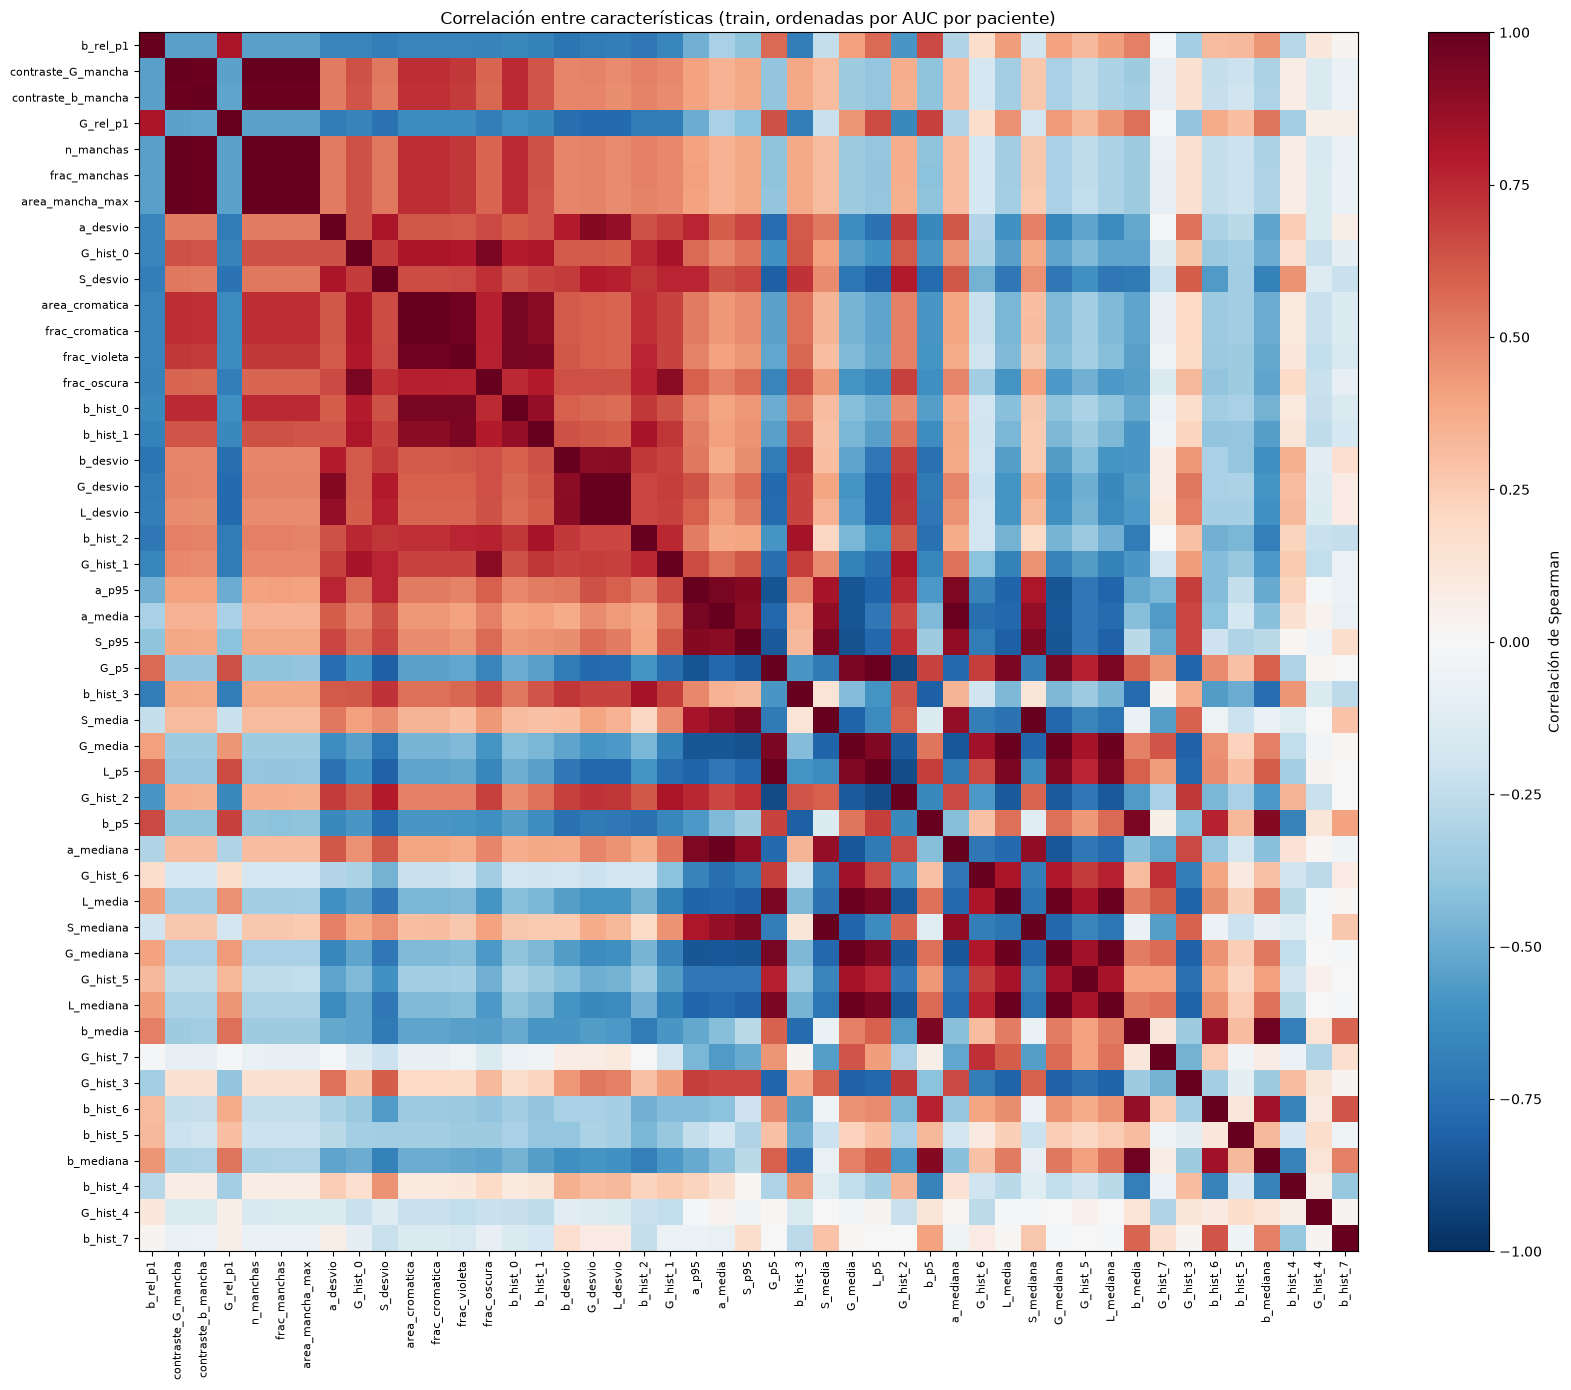

In [7]:
correlacion = train[ranking["caracteristica"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlacion)))
ax.set_xticklabels(correlacion.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(correlacion)))
ax.set_yticklabels(correlacion.index, fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046, label="Correlación de Spearman")
ax.set_title("Correlación entre características (train, ordenadas por AUC por paciente)")
plt.tight_layout()
plt.show()

## 6. Selección exploratoria de características

Regla simple (selección "golosa"):
1. Recorremos las características de mejor a peor **AUC por paciente**.
2. Agregamos una si su AUC por paciente es al menos `AUC_MIN` y **no está muy correlacionada** (|ρ| < `RHO_MAX`) con ninguna ya elegida.

Así nos quedamos con pocas características, buenas y que aportan información distinta.

> **Ojo:** esta selección usa los 6 pacientes de train, así que es una **selección exploratoria previa**. Para una estimación independiente del rendimiento en C5, la selección tiene que repetirse dentro de cada partición de la validación por paciente, o declararse explícitamente como fijada de antemano.

In [8]:
AUC_MIN = 0.8
RHO_MAX = 0.8

seleccionadas = []
for _, fila in ranking.iterrows():
    c = fila["caracteristica"]
    if fila["AUC por paciente (media)"] < AUC_MIN:
        continue
    if all(abs(correlacion.loc[c, s]) < RHO_MAX for s in seleccionadas):
        seleccionadas.append(c)

seleccion = ranking[ranking["caracteristica"].isin(seleccionadas)].copy()
seleccion["seleccionada"] = True
ranking_guardar = ranking.merge(seleccion[["caracteristica", "seleccionada"]], on="caracteristica", how="left")
ranking_guardar["seleccionada"] = ranking_guardar["seleccionada"].fillna(False).astype(bool)
ranking_guardar.to_csv(CARPETA_RESULTADOS / "c4_ranking_color.csv", index=False)

print("Seleccionadas:", seleccionadas)
correlacion.loc[seleccionadas, seleccionadas].round(2)

Seleccionadas: ['b_rel_p1', 'contraste_G_mancha', 'a_desvio', 'G_hist_0', 'frac_violeta', 'b_desvio', 'b_hist_2', 'a_p95']


,b_rel_p1,contraste_G_mancha,a_desvio,G_hist_0,frac_violeta,b_desvio,b_hist_2,a_p95
b_rel_p1,1.00,-0.54,-0.66,-0.66,-0.66,-0.73,-0.71,-0.48
contraste_G_mancha,-0.54,1.00,0.52,0.63,0.70,0.49,0.50,0.40
a_desvio,-0.66,0.52,1.00,0.64,0.62,0.79,0.64,0.76
G_hist_0,-0.66,0.63,0.64,1.00,0.80,0.61,0.76,0.57
frac_violeta,-0.66,0.70,0.62,0.80,1.00,0.62,0.76,0.50
b_desvio,-0.73,0.49,0.79,0.61,0.62,1.00,0.71,0.53
b_hist_2,-0.71,0.50,0.64,0.76,0.76,0.71,1.00,0.51
a_p95,-0.48,0.40,0.76,0.57,0.50,0.53,0.51,1.00


Distribución de las características seleccionadas por clase (train). En el eje Y, la **frecuencia relativa**: cada clase suma 1, para que las parasitadas (que son ~10 veces menos) no queden aplastadas.

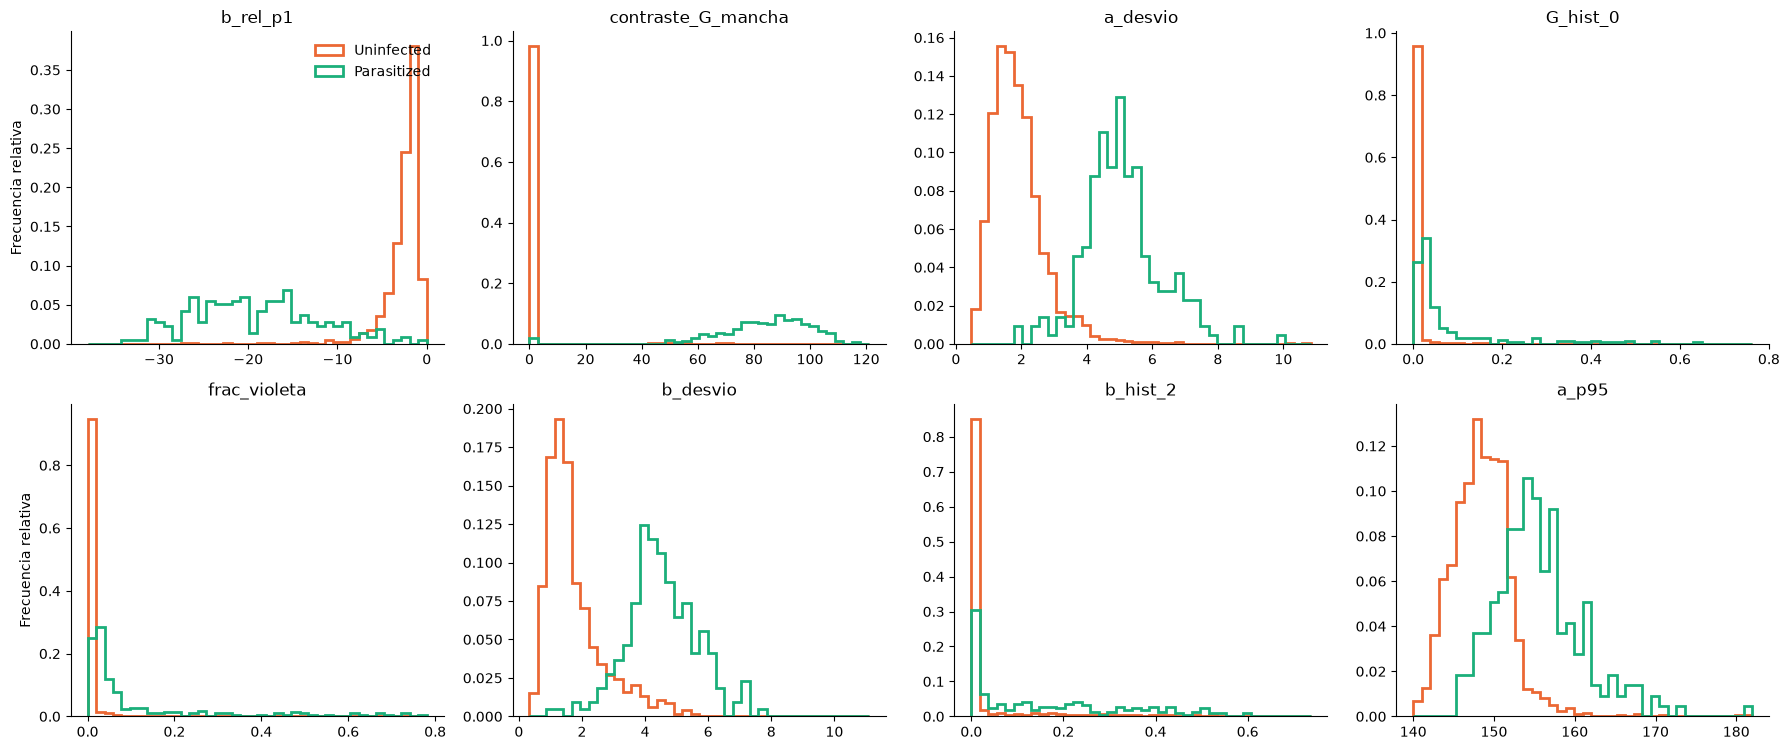

In [9]:
n_col = 4
n_fil = int(np.ceil(len(seleccionadas) / n_col))
fig, ax = plt.subplots(n_fil, n_col, figsize=(4.5 * n_col, 3.8 * n_fil), squeeze=False)
for eje, col in zip(ax.ravel(), seleccionadas):
    bins = np.histogram_bin_edges(train[col], bins=40)
    for clase in [LABEL_UNINFECTED, LABEL_PARASITIZED]:
        valores = train.loc[train["label"] == clase, col]
        pesos = np.ones(len(valores)) / len(valores)  # frecuencia relativa: cada clase suma 1
        eje.hist(valores, bins=bins, weights=pesos, histtype="step", linewidth=2,
                 color=COLOR_CLASE[clase], label=clase)
    eje.set_title(col)
    eje.spines[["top", "right"]].set_visible(False)
for eje in ax.ravel()[len(seleccionadas):]:
    eje.axis("off")
for fila in range(n_fil):
    ax[fila, 0].set_ylabel("Frecuencia relativa")
ax[0, 0].legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

## 7. Conclusiones de C4

Todos los AUC de esta sección son **resultados de desarrollo** sobre train: se calcularon con las mismas células usadas para explorar y seleccionar las características. La evaluación de los criterios de clasificación se hace en C5 (validación por paciente) y en la evaluación final sobre test.

1. **Se calcularon 47 características por célula**, que cubren lo que pide el anteproyecto: **media y desvío** por canal (G, L, a, b, S), **histogramas** de G y b, **proporción de tonos oscuros/violetas** (`frac_oscura`, `frac_violeta`) y **área cromática integrada** (`area_cromatica`). También se agregaron las que surgieron de C1-C3: medianas, percentiles extremos, versiones relativas a la célula y las manchas de C3.
2. **Las mejores siguen siendo las "locales"**: `b_rel_p1` (qué tan violeta es lo más violeta de la célula respecto de su mediana) tiene el mayor AUC por paciente (0.974) y el mejor peor paciente (0.897), seguida por las manchas de C3 (≈0.96). `b_rel_p1` no depende de ningún umbral ajustado con etiquetas, pero sí de la normalización por fondo y de la elección del percentil 1.
3. **El desvío separa mucho mejor que la media.** `a_desvio`, `S_desvio`, `b_desvio` y `G_desvio` tienen AUC por paciente de 0.91-0.96, mientras que las medias quedan en 0.69-0.81 y algunas separan al revés en el peor paciente. Es coherente con lo anterior: el parásito no cambia mucho el color promedio de la célula, pero sí agrega píxeles muy distintos al resto.
4. **El área cromática y la proporción de tonos oscuros/violetas son de las más estables entre pacientes** (`area_cromatica`: AUC por paciente 0.946, peor paciente 0.864; `frac_violeta` 0.937 y 0.833), aunque usan un rango de color absoluto. Funciona porque el rango es muy estricto (más oscuro o más violeta que el 99 % de los píxeles sanos de train). Como ese rango se eligió con las etiquetas de train, en C5 hay que recalcularlo dentro de cada partición o declararlo fijado de antemano.
5. **En los histogramas solo sirven los intervalos extremos:** el más oscuro de G (`G_hist_0`, 0.955) y los más violetas de b (`b_hist_0`, `b_hist_1`, ≈0.92-0.93). Los intervalos del medio separan poco y en algunos pacientes al revés: el resto de la célula es igual en parasitadas y sanas.
6. Muchas características miden casi lo mismo: las de manchas de C3 entre sí, `area_cromatica` con `frac_cromatica`, y los desvíos entre sí.
7. **Selección exploratoria** (AUC por paciente ≥ 0.8 y |ρ| < 0.8 entre ellas): `b_rel_p1`, `contraste_G_mancha`, `a_desvio`, `G_hist_0`, `frac_violeta`, `b_desvio`, `b_hist_2` y `a_p95`. Siguen estando las tres de la versión anterior (`b_rel_p1`, `contraste_G_mancha`, `a_p95`). Varias de las nuevas tienen correlaciones de 0.7-0.8 con las ya elegidas, y algunas tienen un peor paciente bajo (`b_hist_2` 0.665, `b_desvio` 0.734), así que en C5 conviene empezar por las primeras y ver si las demás agregan algo.
8. **Ojo:** el umbral de la máscara C3 y el rango de color de `frac_oscura`, `frac_violeta` y `area_cromatica` se eligieron con estas mismas células de train, así que su AUC puede estar algo inflado.
9. **Para la validación de C5:** no alcanza con tomar este CSV y hacer leave-one-patient-out sobre él, porque varias características dependen de parámetros calculados con **todos** los pacientes de train. Dentro de cada partición, sin el paciente evaluado, hay que recalcular: el **rango oscuro/violeta** (`frac_oscura`, `frac_violeta`, `area_cromatica`, `frac_cromatica`), los **intervalos de los histogramas**, la **selección de características** y los **umbrales** de clasificación. Si se vuelven a ajustar, también los parámetros de la máscara de C3 y la referencia de normalización (en C2 y C3 vimos que esta última casi no influye).

**Código para el pipeline:** las funciones están en `color_stain/color_features.py`. En `main.py` (paso 7) se usa `caracteristicas_celula(crop, mask, fondo)`, con el recorte sin normalizar de cada célula segmentada y `fondo = mediana_fondo(imagen_rgb, campo)` calculado una vez por imagen. Si la máscara de una célula está vacía, la función devuelve `None` (igual que `glcm_celula`), para que el pipeline la saltee.

**Archivos generados (en `color_stain/results/`):**
- `features_color_gt.csv`: las 47 características para las células del GT de **train** (incluidos glóbulos blancos), con el mismo `cell_id` que las características de textura del Bloque B, para poder unirlas en C5. Incluye la columna `label` para este análisis; al clasificar, las etiquetas tienen que mantenerse separadas de las características (contrato del anteproyecto).
- `c4_ranking_color.csv`: el ranking de la sección 4 con la columna `seleccionada`.
- `rangos_color.json`: el rango oscuro/violeta y los intervalos de los histogramas, calculados con train (los usa `color_features.py`).

**Ubicación del CSV:** se guardara los archivos compartidos en `data/shared/features/`. Por ahora queda en `color_stain/results/`